In [72]:
import numpy as np
import pandas as pd
import seaborn as sns
import nflreadpy as nfl

from matplotlib import pyplot as plt

rng = np.random.default_rng()

In [73]:
# load schedule and teams
start = 2000
seasons = [2010 + x for x in range(2025 - start)]   # using data up till 2024 season so that 2025 season can be test set
ld_schedule = nfl.load_schedules(seasons)
ld_teams = nfl.load_teams()

idx = {}
teams = ld_teams['team_abbr']
division = ld_teams['team_division']
for i, team in enumerate(teams):
    idx[team] = i


teams_by_division = {}
for team, div in zip(ld_teams["team_abbr"], ld_teams["team_division"]):
    teams_by_division.setdefault(div, []).append(team)

print(teams_by_division["NFC West"])

['ARI', 'LA', 'LAR', 'SEA', 'SF', 'STL']


In [74]:
# dictionary to maintain abbreviation to full name
atn = {}
for abbr, name in zip(ld_teams['team_abbr'], ld_teams['team_name']):
    atn[abbr] = name

# game statistics
game_type = ld_schedule['game_type']    # REG, WC, DIV, CON, SB
home_team = ld_schedule['home_team']
away_team = ld_schedule['away_team']
week = ld_schedule['week']
location = ld_schedule['location']
result = ld_schedule['result']
overtime = ld_schedule['overtime']

In [75]:
# calculate W/L results and # of games played
W_grid = np.array([([0] * len(teams)) for _ in range(len(teams))])
L_grid = np.array([([0] * len(teams)) for _ in range(len(teams))])

N = 0
wins, losses = {}, {}
for gt, ht, at, wk, l, r, o in zip(game_type, home_team, away_team, week, location, result, overtime):
    if gt == "REG":
        x, y = idx[ht], idx[at]
        if r:
            if r > 0:
                W_grid[x][y] += 1
                L_grid[y][x] += 1
            else:
                W_grid[y][x] += 1
                L_grid[x][y] += 1
            N += 1

    wins = [sum(W_grid[k]) for k in range(len(W_grid))]
    st_scores, st_teams = zip(*sorted(zip(wins, teams), reverse=True))

    rankings = []
    for score, team in zip(list(st_scores), list(st_teams)):
        rankings.append((team, int(score)))

print(N)

4268


In [76]:
wins = [sum(W_grid[k]) for k in range(len(W_grid))]
st_scores, st_teams = zip(*sorted(zip(wins, teams), reverse=True))

rankings = []
for score, team in zip(list(st_scores), list(st_teams)):
    rankings.append((team, int(score)))

print(rankings[:5])

[('NE', 176), ('KC', 173), ('GB', 169), ('PIT', 167), ('SEA', 165)]


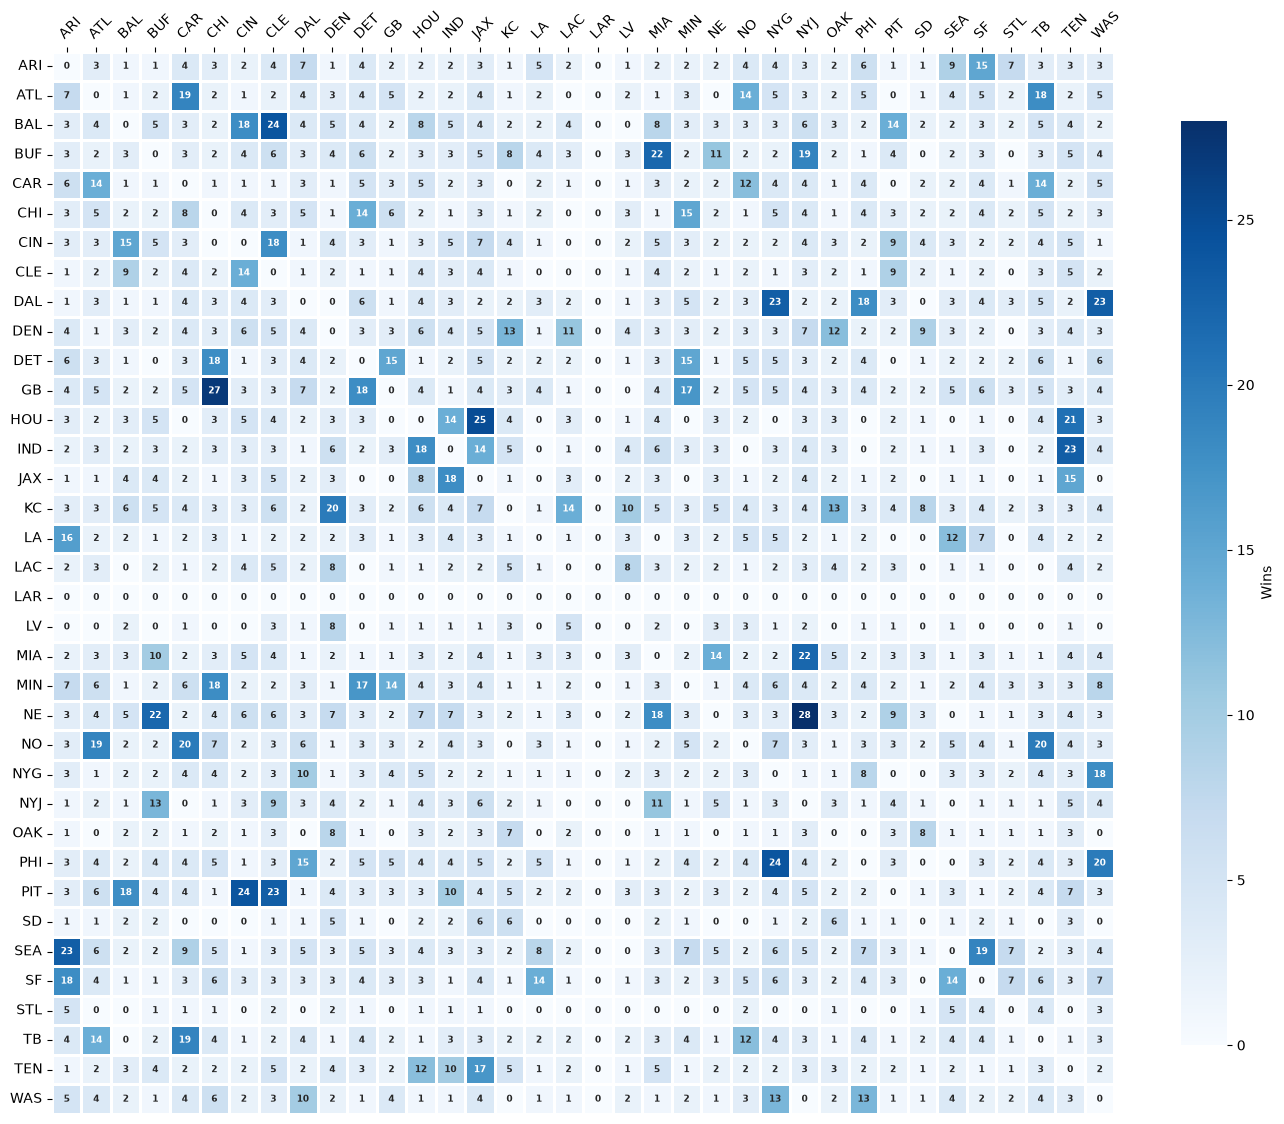

In [77]:
fig, ax = plt.subplots(figsize=(14, 12))

# 2. Plot the wins heatmap using Seaborn
# fmt="g" displays values as standard integers without decimals
# annot_kws ensures the text labels scale down to fit cleanly inside the boxes
sns.heatmap(W_grid, annot=True, fmt="g", cmap="Blues", 
            xticklabels=teams, yticklabels=teams, square=True, 
            linewidths=1, linecolor="white", ax=ax,
            cbar_kws={'label': 'Wins', 'shrink': 0.8},
            annot_kws={"size": 6.5, "weight": "bold"})

# 3. Position the X-axis labels neatly across the top
ax.xaxis.tick_top()
plt.setp(ax.get_xticklabels(), rotation=45, ha="left", rotation_mode="anchor")

fig.tight_layout()
plt.show()

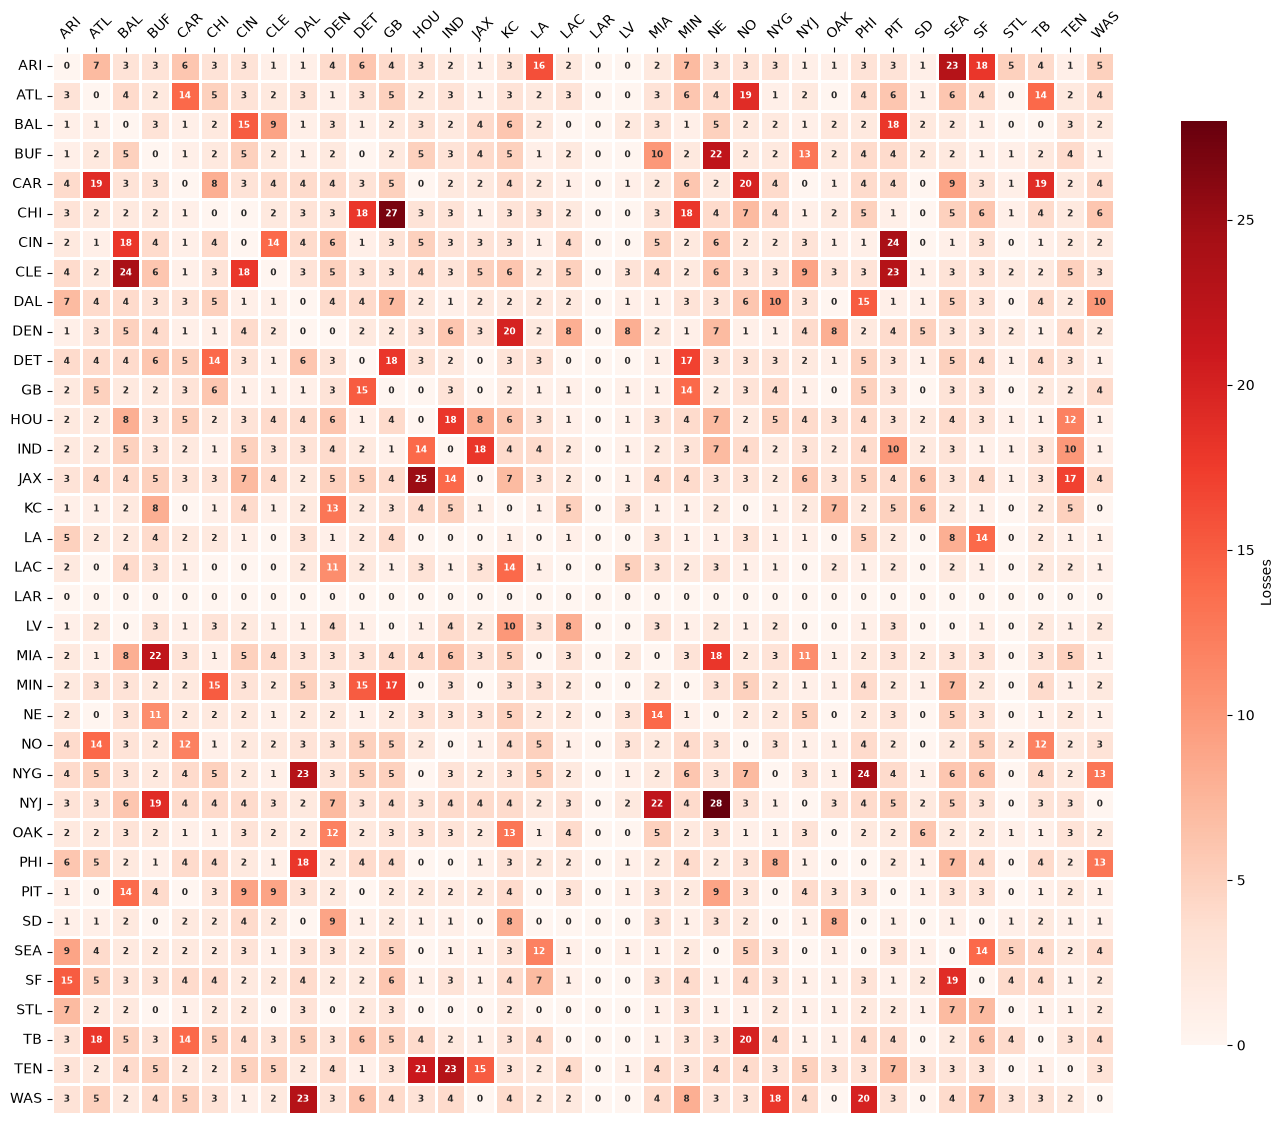

In [78]:
fig, ax = plt.subplots(figsize=(14, 12))

# 2. Plot heatmap using Seaborn
# fmt="g" displays values as standard integers without decimals
# annot_kws sets a readable bold font size that fits nicely inside the grid boxes
sns.heatmap(L_grid, annot=True, fmt="g", cmap="Reds", 
            xticklabels=teams, yticklabels=teams, square=True, 
            linewidths=1, linecolor="white", ax=ax,
            cbar_kws={'label': 'Losses', 'shrink': 0.8},
            annot_kws={"size": 6.5, "weight": "bold"})

# 3. Position the X-axis labels at the top and tilt them 45 degrees
ax.xaxis.tick_top()
plt.setp(ax.get_xticklabels(), rotation=45, ha="left", rotation_mode="anchor")

fig.tight_layout()
plt.show()


In [79]:
win_prob = np.array([([0.5] * len(teams)) for _ in range(len(teams))])
loss_prob = np.array([([0.5] * len(teams)) for _ in range(len(teams))])
for i in range(len(W_grid)):
    for j in range(len(W_grid[i])):
        n = W_grid[i][j] + W_grid[j][i]
        if n != 0:
            win_prob[i][j] = W_grid[i][j] / n
            loss_prob[i][j] = L_grid[i][j] / n


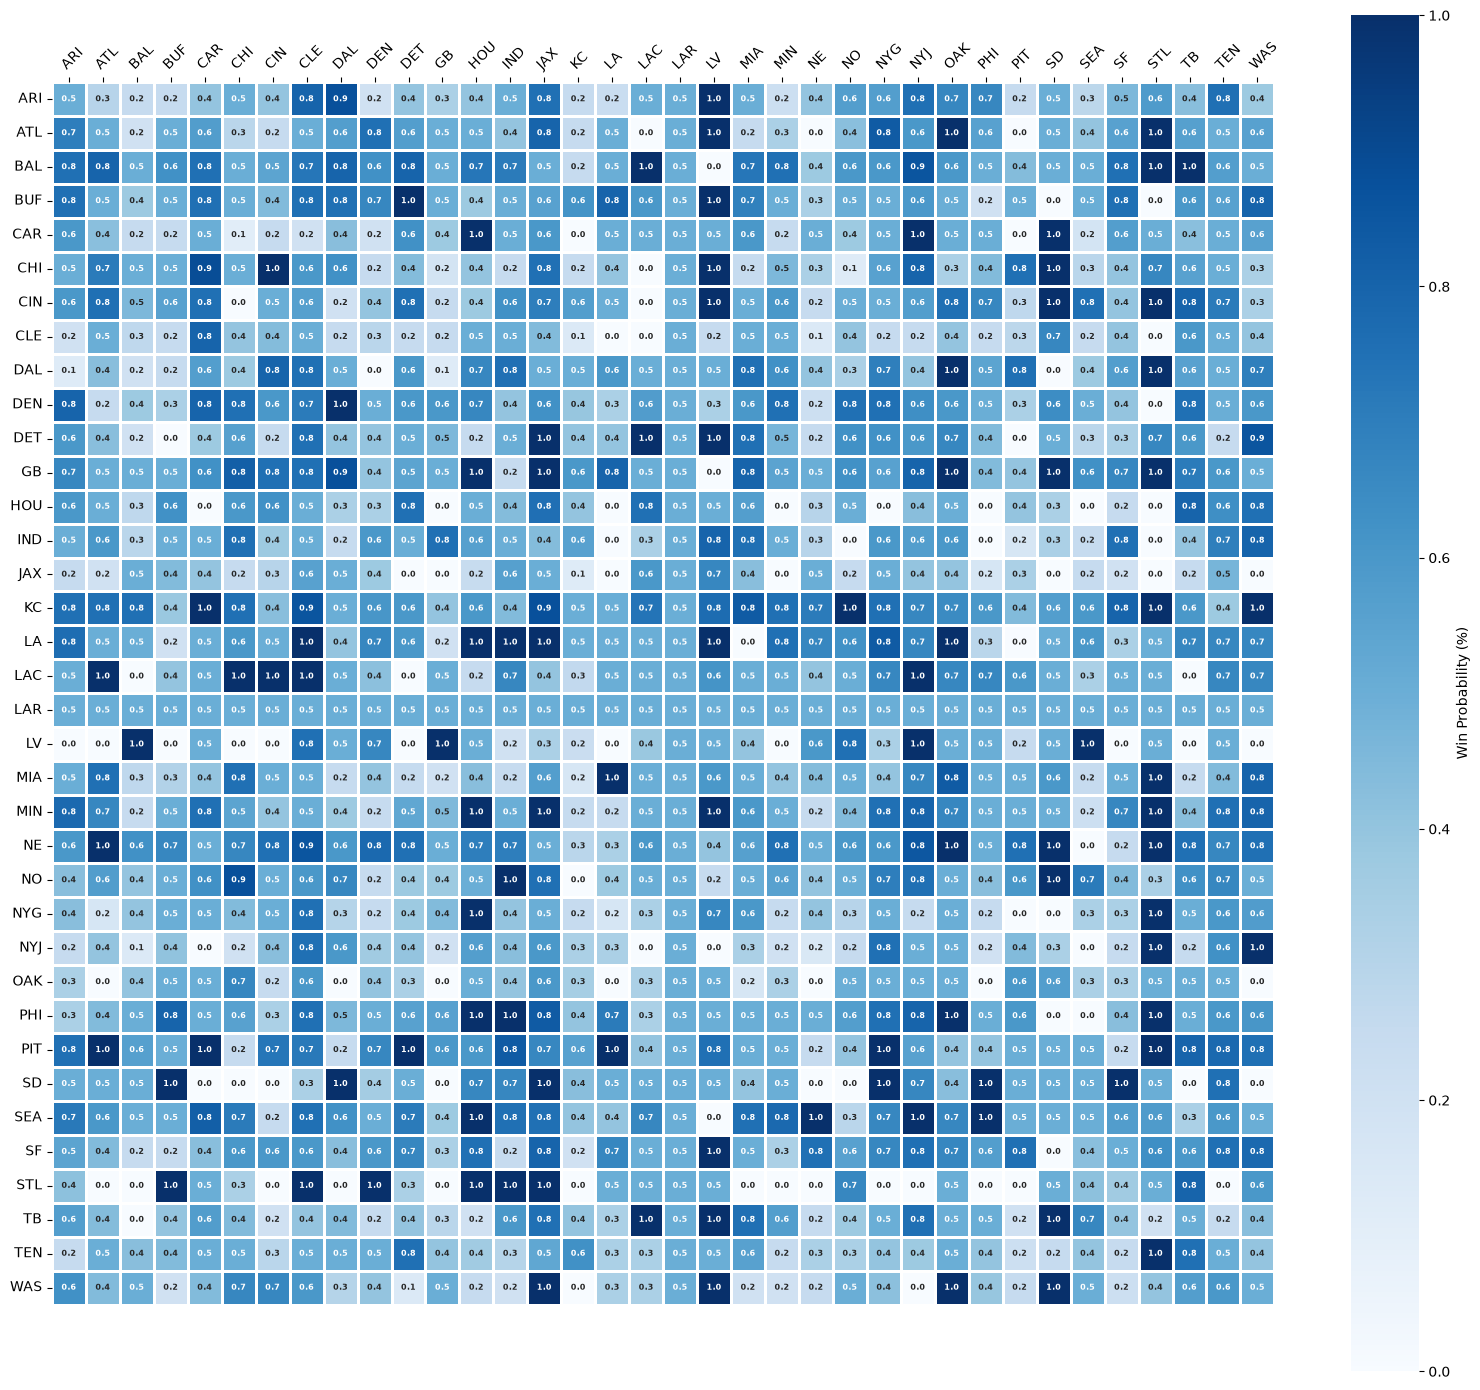

In [80]:
"""
How to interpret: each row consists of win-rate probabilities for the team on the y-axis against the team on the x-axis
"""

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(win_prob, annot=True, fmt=".1f", cmap="Blues", 
            xticklabels=teams, yticklabels=teams, square=True, 
            linewidths=1, linecolor="white", ax=ax,
            cbar_kws={'label': 'Win Probability (%)'},
            annot_kws={"size": 6, "weight": "bold"})

ax.xaxis.tick_top()
plt.setp(ax.get_xticklabels(), rotation=45, ha="left", rotation_mode="anchor")
fig.tight_layout()
plt.show()

In [81]:
def simulate_regular_season(season):
    ld_test = nfl.load_schedules(season)

    # game statistics
    game_type = ld_test['game_type']    # REG, WC, DIV, CON, SB
    home_team = ld_test['home_team']
    away_team = ld_test['away_team']
    week = ld_test['week']
    location = ld_test['location']
    result = ld_test['result']
    overtime = ld_test['overtime']

    wins = {}
    for gt, ht, at, wk, l, r, o in zip(game_type, home_team, away_team, week, location, result, overtime):
        if gt == "REG":
            x, y = idx[ht], idx[at]

            state = [ht, at]
            prob = [win_prob[x][y], 1 - win_prob[x][y]]

            winner = rng.choice(state, p=prob)
            wins[winner] = wins.get(winner, 0) + 1
            
    return wins

def determine_playoff_teams(wins, teams_by_division, conference):
    conference_divisions = {
        division: teams
        for division, teams in teams_by_division.items()
        if division.startswith(conference)
    }

    division_winners = {}
    non_division_winners = []

    for division, teams in conference_divisions.items():
        # Keep only teams that exist in the wins dictionary
        valid_teams = [team for team in teams if team in wins]

        # Simplified: highest number of wins wins the division
        winner = max(valid_teams, key=lambda team: wins[team])
        division_winners[division] = winner

        # Everyone else is eligible for a wild card
        non_division_winners.extend(
            team for team in valid_teams if team != winner
        )

    # Simplified: highest win totals get wild cards
    wild_cards = sorted(
        non_division_winners,
        key=lambda team: wins[team],
        reverse=True
    )[:3]

    playoff_teams = list(division_winners.values()) + wild_cards

    return division_winners, wild_cards, playoff_teams

season = 2025
wins = simulate_regular_season(season)

afc_division_winners, afc_wild_cards, afc_playoffs = (determine_playoff_teams(wins, teams_by_division, "AFC"))
nfc_division_winners, nfc_wild_cards, nfc_playoffs = (determine_playoff_teams(wins, teams_by_division, "NFC"))

# print("AFC division winners:", afc_division_winners)
# print("AFC wild cards:", afc_wild_cards)
print("AFC playoff teams:", afc_playoffs)

# print("NFC division winners:", nfc_division_winners)
# print("NFC wild cards:", nfc_wild_cards)
print("NFC playoff teams:", nfc_playoffs)

AFC playoff teams: ['BAL', 'NE', 'KC', 'HOU', 'DEN', 'LAC', 'CIN']
NFC playoff teams: ['SEA', 'ATL', 'CHI', 'PHI', 'SF', 'LA', 'GB']


In [82]:
def create_seeds(division_winners, wild_cards, wins):
    ranked_division_winners = sorted(
        division_winners.values(),
        key=lambda team: wins[team],
        reverse=True
    )

    ranked_wild_cards = sorted(
        wild_cards,
        key=lambda team: wins[team],
        reverse=True
    )

    seeds = {}

    for seed, team in enumerate(ranked_division_winners, start=1):
        seeds[seed] = team

    for seed, team in enumerate(ranked_wild_cards, start=5):
        seeds[seed] = team

    return seeds

def wild_card_matchups(seeds):
    return [(seeds[2], seeds[7]), (seeds[3], seeds[6]),(seeds[4], seeds[5])]


afc_seeds = create_seeds(afc_division_winners,afc_wild_cards,wins)
nfc_seeds = create_seeds(nfc_division_winners,nfc_wild_cards,wins)

print("AFC seeds:", afc_seeds)
print("AFC Wild Card:", wild_card_matchups(afc_seeds))
print("NFC seeds:", nfc_seeds)
print("NFC Wild Card:", wild_card_matchups(nfc_seeds))

AFC seeds: {1: 'KC', 2: 'NE', 3: 'BAL', 4: 'HOU', 5: 'DEN', 6: 'LAC', 7: 'CIN'}
AFC Wild Card: [('NE', 'CIN'), ('BAL', 'LAC'), ('HOU', 'DEN')]
NFC seeds: {1: 'SEA', 2: 'CHI', 3: 'PHI', 4: 'ATL', 5: 'SF', 6: 'LA', 7: 'GB'}
NFC Wild Card: [('CHI', 'GB'), ('PHI', 'LA'), ('ATL', 'SF')]


In [83]:
afc_bracket = [
    f"{team1} vs {team2}"
    for team1, team2 in wild_card_matchups(afc_seeds)
]

nfc_bracket = [
    f"{team1} vs {team2}"
    for team1, team2 in wild_card_matchups(nfc_seeds)
]

print(afc_bracket)
print(nfc_bracket)

['NE vs CIN', 'BAL vs LAC', 'HOU vs DEN']
['CHI vs GB', 'PHI vs LA', 'ATL vs SF']
